# Lab Day 10: Finetune Qwen3-VL-4B (LoRA) để định vị hư hại mặt đường
Đọc `README.md` và `GUIDE.md` trước. Notebook này chỉ là **khung**: bạn tự viết mã theo pseudo code trong GUIDE.

## 0. Môi trường (Colab T4)

In [ ]:
# Runtime → Change runtime type → T4 GPU
from pathlib import Path
import os
import subprocess
import sys

if not Path("requirements-colab.txt").is_file():
    repo_dir = Path("/content/K4-Track-4-Day10-VisionLanguageModel")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", "https://github.com/Tiendung3tzz/K4-Track-4-Day10-VisionLanguageModel.git", str(repo_dir)], check=True)
    os.chdir(repo_dir)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))
!nvidia-smi -L
!pip -q install -r requirements-colab.txt
!python -m pytest -q


In [ ]:
# Kaggle: dùng Colab Secrets. Không ghi khoá vào notebook.
import os
from google.colab import userdata

try:
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
except userdata.SecretNotFoundError:
    print("Chưa có Kaggle Secrets; dùng URL zip công khai ở cell dữ liệu.")


## 1. Dữ liệu: tải và chia split

In [1]:
from pathlib import Path
import os
import subprocess
import sys

if Path("work/raw").is_dir() and any(Path("work/raw").iterdir()):
    source = ["--source", "work/raw"]
elif os.environ.get("KAGGLE_KEY"):
    source = ["--kaggle"]
else:
    source = ["--zip", "https://www.kaggle.com/api/v1/datasets/download/lorenzoarcioni/road-damage-dataset-potholes-cracks-and-manholes"]
subprocess.run([sys.executable, "scripts/prepare_data.py", *source], check=True)


Kiểm tra bước 1 trên máy local (CPU):
dataset_version : d10-21e4070301
  train  1422 ảnh  boxes={'pothole': 1074, 'crack': 1750, 'manhole': 691}
  val     276 ảnh  boxes={'pothole': 66, 'crack': 470, 'manhole': 103}
  test    311 ảnh  boxes={'pothole': 121, 'crack': 299, 'manhole': 163}


dataset_version: d10-21e4070301
train images = 1422 boxes = {'manhole': 691, 'pothole': 1074, 'crack': 1750}
val images = 276 boxes = {'crack': 470, 'manhole': 103, 'pothole': 66}
test images = 311 boxes = {'crack': 299, 'manhole': 163, 'pothole': 121}


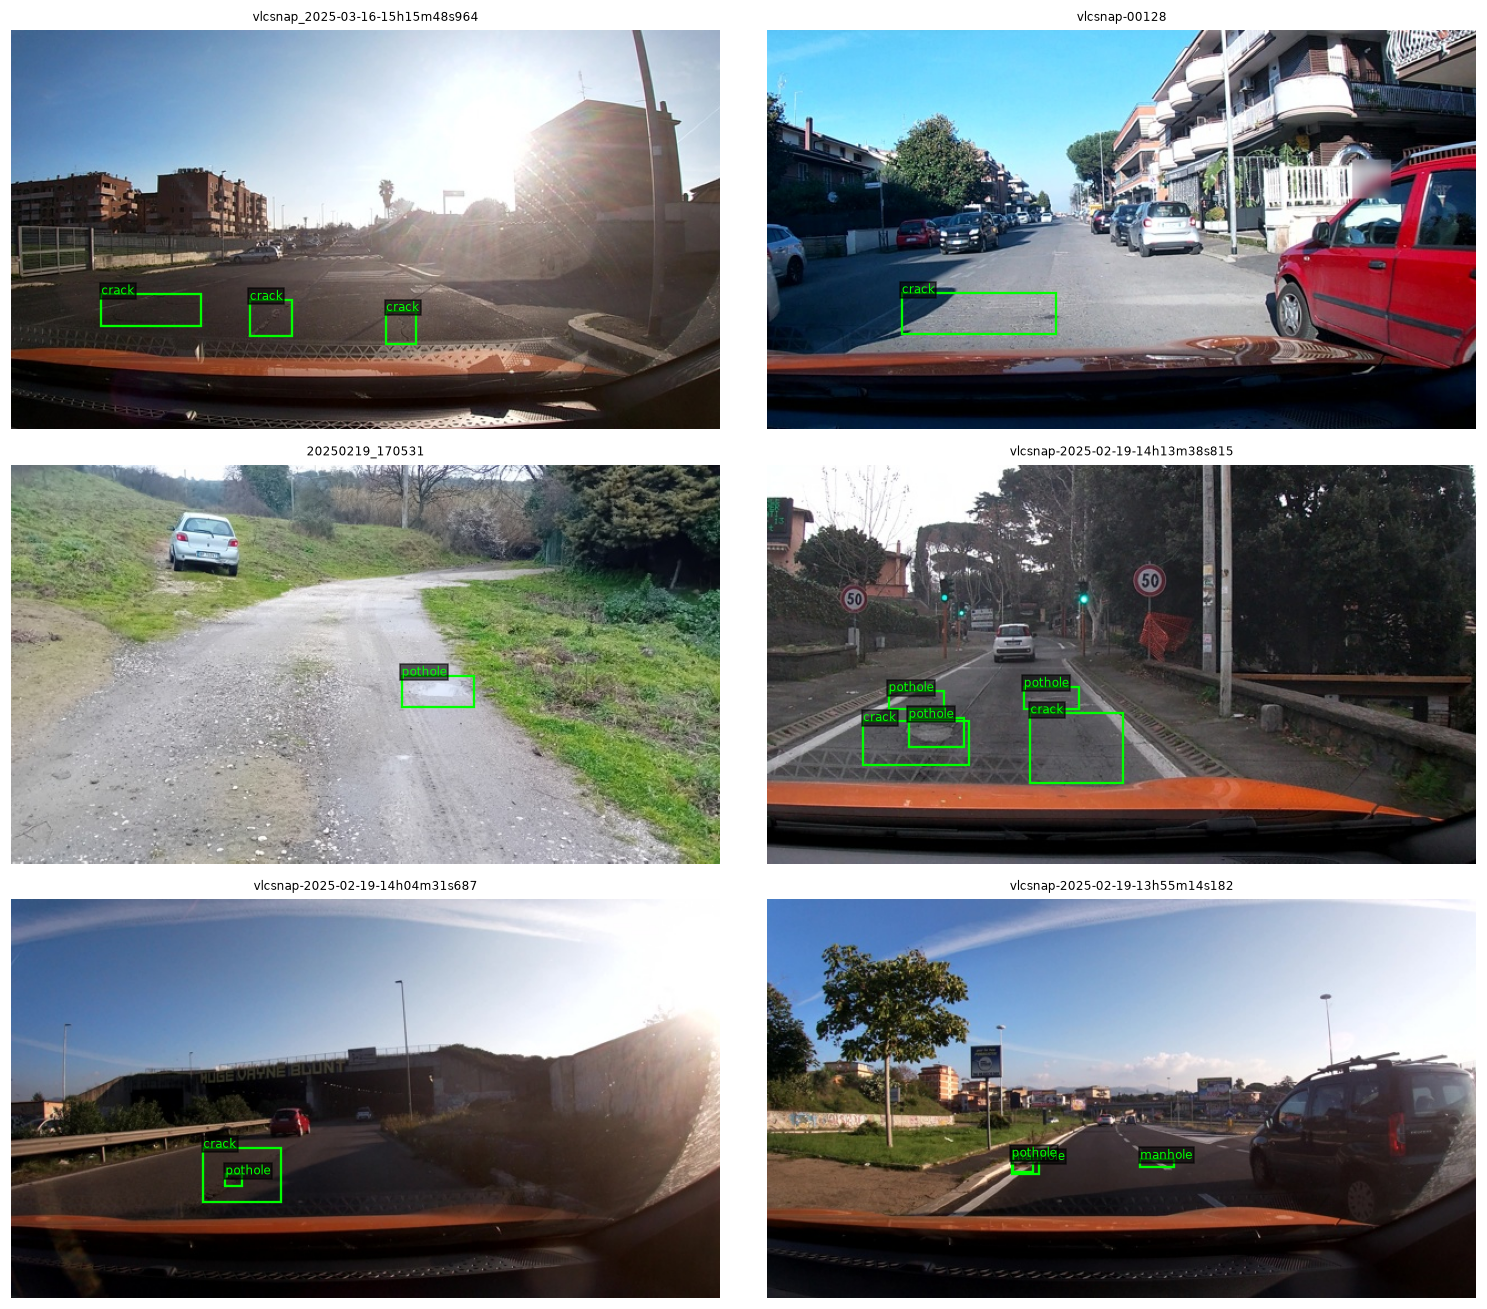

In [2]:
import json
import math
import random
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scripts.labcommon import CLASSES, read_jsonl

DATA_DIR = Path("data")
WORK_DIR = Path("work")
WORK_DIR.mkdir(exist_ok=True)
splits = {
    name: read_jsonl(DATA_DIR / "splits" / f"{name}.jsonl")
    for name in ("train", "val", "test")
}
dataset_meta = json.loads((DATA_DIR / "splits/meta.json").read_text(encoding="utf-8"))
print("dataset_version:", dataset_meta["dataset_version"])

sessions = {name: {row["session"] for row in rows} for name, rows in splits.items()}
for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
    assert sessions[a].isdisjoint(sessions[b]), f"Session giao nhau: {a}, {b}"

for name, rows in splits.items():
    counts = Counter(obj["label"] for row in rows for obj in row["objects"])
    assert len({row["image_id"] for row in rows}) == len(rows)
    assert dataset_meta["counts"][name] == {
        "images": len(rows), "boxes": {label: counts[label] for label in CLASSES}
    }
    print(name, "images =", len(rows), "boxes =", dict(counts))

def open_image(entry):
    with Image.open(DATA_DIR / entry["image_path"]) as source:
        image = source.convert("RGB")
    assert image.size == (entry["width"], entry["height"])
    return image

samples = random.Random(42).sample(splits["train"], 6)
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, entry in zip(axes.flat, samples):
    ax.imshow(open_image(entry))
    for obj in entry["objects"]:
        xc, yc, w, h = obj["yolo"]
        x1, y1 = (xc - w/2)*entry["width"], (yc - h/2)*entry["height"]
        ax.add_patch(Rectangle((x1, y1), w*entry["width"], h*entry["height"],
                               fill=False, edgecolor="lime", linewidth=1.5))
        ax.text(x1, y1, obj["label"], color="lime", fontsize=8,
                bbox={"facecolor": "black", "alpha": 0.6, "pad": 1})
    ax.set_title(entry["image_id"], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Nhãn: YOLO → JSON thang 0–1000

train box có chiều rộng/cao bằng 0: 1
val box có chiều rộng/cao bằng 0: 0
test box có chiều rộng/cao bằng 0: 0
Sai số quy ngược pixel lớn nhất: 0.32


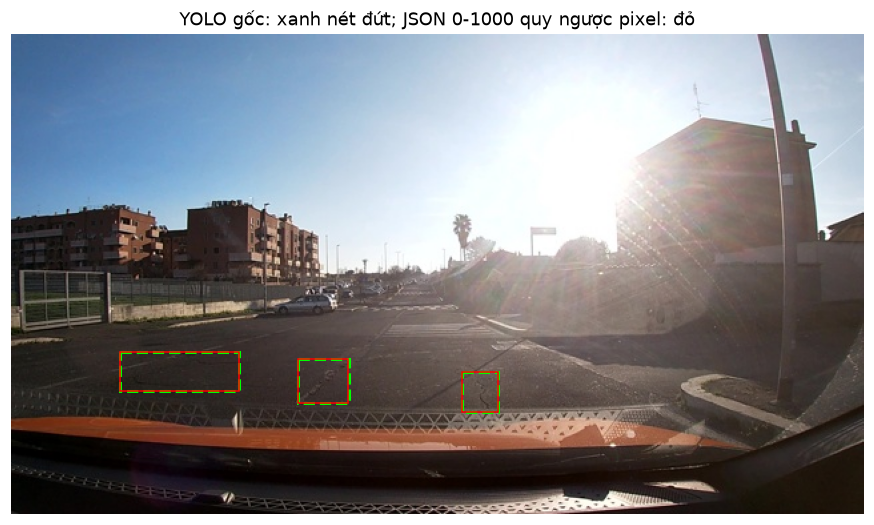

In [3]:
def yolo_to_box(label, yolo):
    xc, yc, w, h = yolo
    coords = [(xc-w/2)*1000, (yc-h/2)*1000,
              (xc+w/2)*1000, (yc+h/2)*1000]
    return {"label": label,
            "bbox_2d": [max(0, min(1000, int(round(v)))) for v in coords]}

def objects_to_answer(objects):
    boxes = [yolo_to_box(obj["label"], obj["yolo"]) for obj in objects]
    # Dataset có một box train với h=0: loại khỏi đáp án SFT để JSON hợp lệ.
    # Không thay dữ liệu gốc hoặc ground truth của công cụ chấm.
    boxes = [box for box in boxes
             if box["bbox_2d"][2] > box["bbox_2d"][0]
             and box["bbox_2d"][3] > box["bbox_2d"][1]]
    boxes.sort(key=lambda box: (box["bbox_2d"][1], box["bbox_2d"][0]))
    return json.dumps(boxes, ensure_ascii=False, separators=(",", ":"))

PROMPT = (
    "Locate all road damage in this dashcam image. Allowed labels: pothole, crack, manhole. "
    "Return ONLY a JSON list with one object per region, using the keys label and bbox_2d. "
    "bbox_2d is [x1,y1,x2,y2], the top-left and bottom-right corners. "
    "Use integer coordinates normalized to 0-1000 independently along image width and height. "
    "Sort regions from top to bottom then left to right. If no damage is visible, return []."
)

assert yolo_to_box("pothole", [0.5, 0.5, 0.2, 0.2])["bbox_2d"] == [400, 400, 600, 600]
assert objects_to_answer([]) == "[]"
for name, rows in splits.items():
    invalid = sum(
        obj["yolo"][2] == 0 or obj["yolo"][3] == 0
        for row in rows for obj in row["objects"]
    )
    print(name, "box có chiều rộng/cao bằng 0:", invalid)

max_pixel_error = 0.0
for rows in splits.values():
    for row in rows:
        for obj in row["objects"]:
            xc, yc, w, h = obj["yolo"]
            expected = [(xc-w/2)*row["width"], (yc-h/2)*row["height"],
                        (xc+w/2)*row["width"], (yc+h/2)*row["height"]]
            box = yolo_to_box(obj["label"], obj["yolo"])["bbox_2d"]
            for value, target, extent in zip(box, expected,
                                             [row["width"],row["height"]]*2):
                error = abs(value*extent/1000-max(0,min(extent,target)))
                assert error <= extent/2000+1e-6
                max_pixel_error = max(max_pixel_error,error)
print("Sai số quy ngược pixel lớn nhất:", round(max_pixel_error, 6))

entry = samples[0]
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(open_image(entry))
for obj in entry["objects"]:
    xc, yc, w, h = obj["yolo"]
    ax.add_patch(Rectangle(((xc-w/2)*entry["width"],(yc-h/2)*entry["height"]),
                           w*entry["width"],h*entry["height"],fill=False,
                           edgecolor="lime",linestyle="--",linewidth=2))
for box in json.loads(objects_to_answer(entry["objects"])):
    x1, y1, x2, y2 = box["bbox_2d"]
    x1, x2 = x1*entry["width"]/1000, x2*entry["width"]/1000
    y1, y2 = y1*entry["height"]/1000, y2*entry["height"]/1000
    ax.add_patch(Rectangle((x1, y1), x2-x1, y2-y1, fill=False, edgecolor="red"))
ax.set_title("YOLO gốc: xanh nét đứt; JSON 0-1000 quy ngược pixel: đỏ")
ax.axis("off")
plt.show()

## 3. E0: zero-shot

In [ ]:
# YOUR CODE HERE: nạp model 4-bit, suy luận trên test → work/e0.jsonl (GUIDE bước 3)

In [ ]:
!python scripts/score.py --pred work/e0.jsonl --name E0 --out report/evidence/e0.json

## 4. Dựng dữ liệu huấn luyện: chat template và mask loss

In [ ]:
# YOUR CODE HERE: encode_example() và collate() (GUIDE bước 4)

## 5. Setup LoRA / đóng băng cho E1, E2, E3

In [ ]:
# YOUR CODE HERE: apply_setup(model, setup) (GUIDE bước 5)

## 6. Vòng huấn luyện

In [ ]:
# YOUR CODE HERE: vòng train, lưu adapter + run.json (GUIDE bước 6)

## 7. Suy luận và chấm E1–E3

In [ ]:
# YOUR CODE HERE: suy luận test → work/eN.jsonl rồi chạy scripts/score.py với --meta (GUIDE bước 7)

## 8. E4 (ablation tự chọn) và E5 (tuỳ chọn, GRPO)

In [ ]:
# YOUR CODE HERE: GUIDE bước 8 và 9